# Практичне завдання №3
## Дослідження ефективності TF-IDF зважених ембеддингів для детекції текстів, згенерованих великими мовними моделями
**Мулявко Софія Марківна · Феі-46**

**Мета.** Побудувати субслівні FastText-ембеддинги, порівняти Mean Pooling і TF-IDF Weighted Mean та перевірити їх у SVM (RBF), Logistic Regression і KNN. Факторний план: два представлення × три класифікатори; залежні змінні — F1 macro, Accuracy, Balanced Accuracy та ROC-AUC.

**Гіпотеза методички:** зважування TF-IDF підсилює специфічну лексику й може поліпшити лінійну роздільність. Це перевіряється результатами, а не приймається наперед.

Послідовність відповідає методичці: теорія й агрегація — с. 1–2; первинний аналіз і spaCy — с. 3–4; FastText та векторизація — с. 4; класифікація, візуалізація та п'ять дослідницьких питань — с. 5. Окремий звіт не потрібний: код, результати й пояснення містяться тут.

### Запуск і відтворюваність
Потрібен Python 3.12 і Jupyter. У новому віртуальному середовищі встановіть залежності командою нижче, відкрийте цей файл і виконайте **Restart Kernel → Run All**. Команди встановлення наведено як інструкцію; notebook не змінює середовище автоматично. Дані вбудовані як gzip/base64, тому для їх відновлення мережа не потрібна. Модель spaCy встановлюється один раз.

```bash
python -m pip install numpy==2.5.4 pandas==3.1.0 scipy==1.18.1 matplotlib==3.11.2 scikit-learn==1.9.1 gensim==4.4.0 spacy==3.8.18 nbformat nbclient ipykernel tabulate
python -m spacy download en_core_web_sm
```

Точні версії фактичного запуску виводяться далі. FastText працює в одному потоці (у прикладі методички — чотири): це усуває недетермінований порядок оновлень. Параметри векторів і класифікаторів збережено. Зерно — 42; стабільна хеш-функція FastText задана явно. Для BLAS/OpenMP перед імпортами задано один потік; між платформами можливі малі числові відмінності. Підбір параметрів на тесті не проводиться.

Повторний запуск створить лише папку `practice3_results` поруч із notebook із CSV/JSON результатів і PNG графіків.

In [1]:
import os
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[name] = "1"
import io, json, base64, gzip, hashlib, platform, importlib.metadata as metadata
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import scipy
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import spacy
from gensim.models import FastText
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.manifold import TSNE
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, silhouette_score,
    pairwise_distances)
from IPython.display import display, Markdown, Image
SEED = 42
np.random.seed(SEED)
OUT = Path("practice3_results")
OUT.mkdir(exist_ok=True)
versions = {name: metadata.version(name) for name in
    ["numpy", "pandas", "scipy", "matplotlib", "scikit-learn", "gensim", "spacy", "en_core_web_sm"]}
print("Python", platform.python_version())
print(json.dumps(versions, indent=2))

Python 3.12.16
{
  "numpy": "2.5.4",
  "pandas": "3.1.0",
  "scipy": "1.18.1",
  "matplotlib": "3.11.2",
  "scikit-learn": "1.9.1",
  "gensim": "4.4.0",
  "spacy": "3.8.18",
  "en_core_web_sm": "3.8.0"
}


In [2]:
# Стиль mpl_style.apply вбудований для самодостатності notebook.
COL = {'primary':'#2A78D6','focus':'#EB6834','total':'#52514E','muted':'#C9CED6',
       'other':'#BFBFBF','grid':'#E3E3E3','axis':'#BFBFBF','text':'#262626','text2':'#595959'}
CAT = ['#2A78D6','#E87BA4','#4A3AA7','#1BAF7A','#EB6834']
def apply():
    """Глобальний стиль: без верхньої/правої рамки, тонка сітка лише по осі значень, 9-11 пт."""
    matplotlib.rcParams.update({
        'font.family': 'DejaVu Sans', 'font.size': 9,
        'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlecolor': COL['text'],
        'axes.titlelocation': 'left', 'axes.titlepad': 10,
        'axes.labelsize': 9, 'axes.labelcolor': COL['text2'],
        'axes.edgecolor': COL['axis'], 'axes.linewidth': 0.6,
        'axes.spines.top': False, 'axes.spines.right': False,
        'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': COL['grid'], 'grid.linewidth': 0.6,
        'axes.axisbelow': True,
        'xtick.color': COL['text2'], 'ytick.color': COL['text2'],
        'xtick.major.size': 0, 'ytick.major.size': 0,
        'legend.frameon': False, 'legend.fontsize': 9,
        'lines.linewidth': 2.0, 'lines.markersize': 5,
        'axes.prop_cycle': matplotlib.cycler(color=CAT),
        'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.05,
        'figure.dpi': 100,
    })
apply()
COLORS = {0: COL['primary'], 1: COL['focus']}
NAMES = {0: 'Human', 1: 'AI'}
def show_figure(fig, name):
    fig.tight_layout()
    path = OUT / name
    fig.savefig(path, dpi=300)
    plt.close(fig)
    display(Image(filename=str(path), width=760))
def table(frame, title, digits=4):
    display(Markdown('**' + title + '**'))
    display(Markdown(frame.to_markdown(index=False, floatfmt=f'.{digits}f')))

### Джерело та структура даних
Використано [AI vs Human Text Classification Dataset 2026 на Kaggle](https://www.kaggle.com/datasets/alitaqishah/ai-vs-human-text-classification-dataset-2026), автор сторінки — `alitaqishah`. Завантаження: [публічний API ZIP](https://www.kaggle.com/api/v1/datasets/download/alitaqishah/ai-vs-human-text-classification-dataset-2026). Нижче наведені дата отримання, розмір і SHA-256 саме використаного CSV. Вбудована копія не залежить від майбутніх змін сторінки.

Вхід класифікатора — **лише `text_content`**; `label` — ціль, Human=0, AI=1. `text_id` — ідентифікатор; `source_model`, `domain`, `topic_hint`, `generation_method` — описові метадані; `word_count`, `avg_sentence_length` — надані автором характеристики. Вони не є ознаками моделей. Кількість слів для аналізу перераховується з тексту.

У таблиці 1 наведено розміри класів і розподіл довжин до очищення, на рисунку 1 — гістограми з однаковими межами інтервалів.

{
  "title": "AI vs Human Text Classification Dataset 2026",
  "page_url": "https://www.kaggle.com/datasets/alitaqishah/ai-vs-human-text-classification-dataset-2026",
  "download_url": "https://www.kaggle.com/api/v1/datasets/download/alitaqishah/ai-vs-human-text-classification-dataset-2026",
  "accessed_utc": "2026-11-03T13:56:20.919465+00:00",
  "csv": "ai_vs_human_text_2026.csv",
  "bytes": 696551,
  "sha256": "9150ddbb4a90a21f7825b8400adeefcc4dd1fcb06241121bac6ef385b3a48c3a"
}
Розмір CSV: (2000, 9)


,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a se...,gene editing ethics,27,13.5,template+human_variation
1,TXT_0002,human,human,social,update on election integrity concerns: it's co...,election integrity concerns,20,10.0,template+human_variation
2,TXT_0003,ai,gemini-2.0,news,Analysts are closely watching developments rel...,climate change adaptation strategies,39,13.0,style_simulation


**Таблиця 1 — Класи й довжини вихідних текстів, слів**

| label   |   count |   min |   median |   mean |   max |
|:--------|--------:|------:|---------:|-------:|------:|
| ai      |     666 |    23 |    39.00 |  38.00 |    50 |
| human   |    1334 |    19 |    36.00 |  36.51 |    52 |

Пропуски за полями: {'text_id': 0, 'label': 0, 'source_model': 0, 'domain': 0, 'text_content': 0, 'topic_hint': 0, 'word_count': 0, 'avg_sentence_length': 0, 'generation_method': 0, 'n_words': 0}
Дослівні дублікати text_content: 1034
Тексти коротші за 5 слів: 0
Розбіжності з полем word_count: 0
Походження записів за метаданими:


,label,generation_method,count
0,ai,style_simulation,666
1,human,template+human_variation,1334


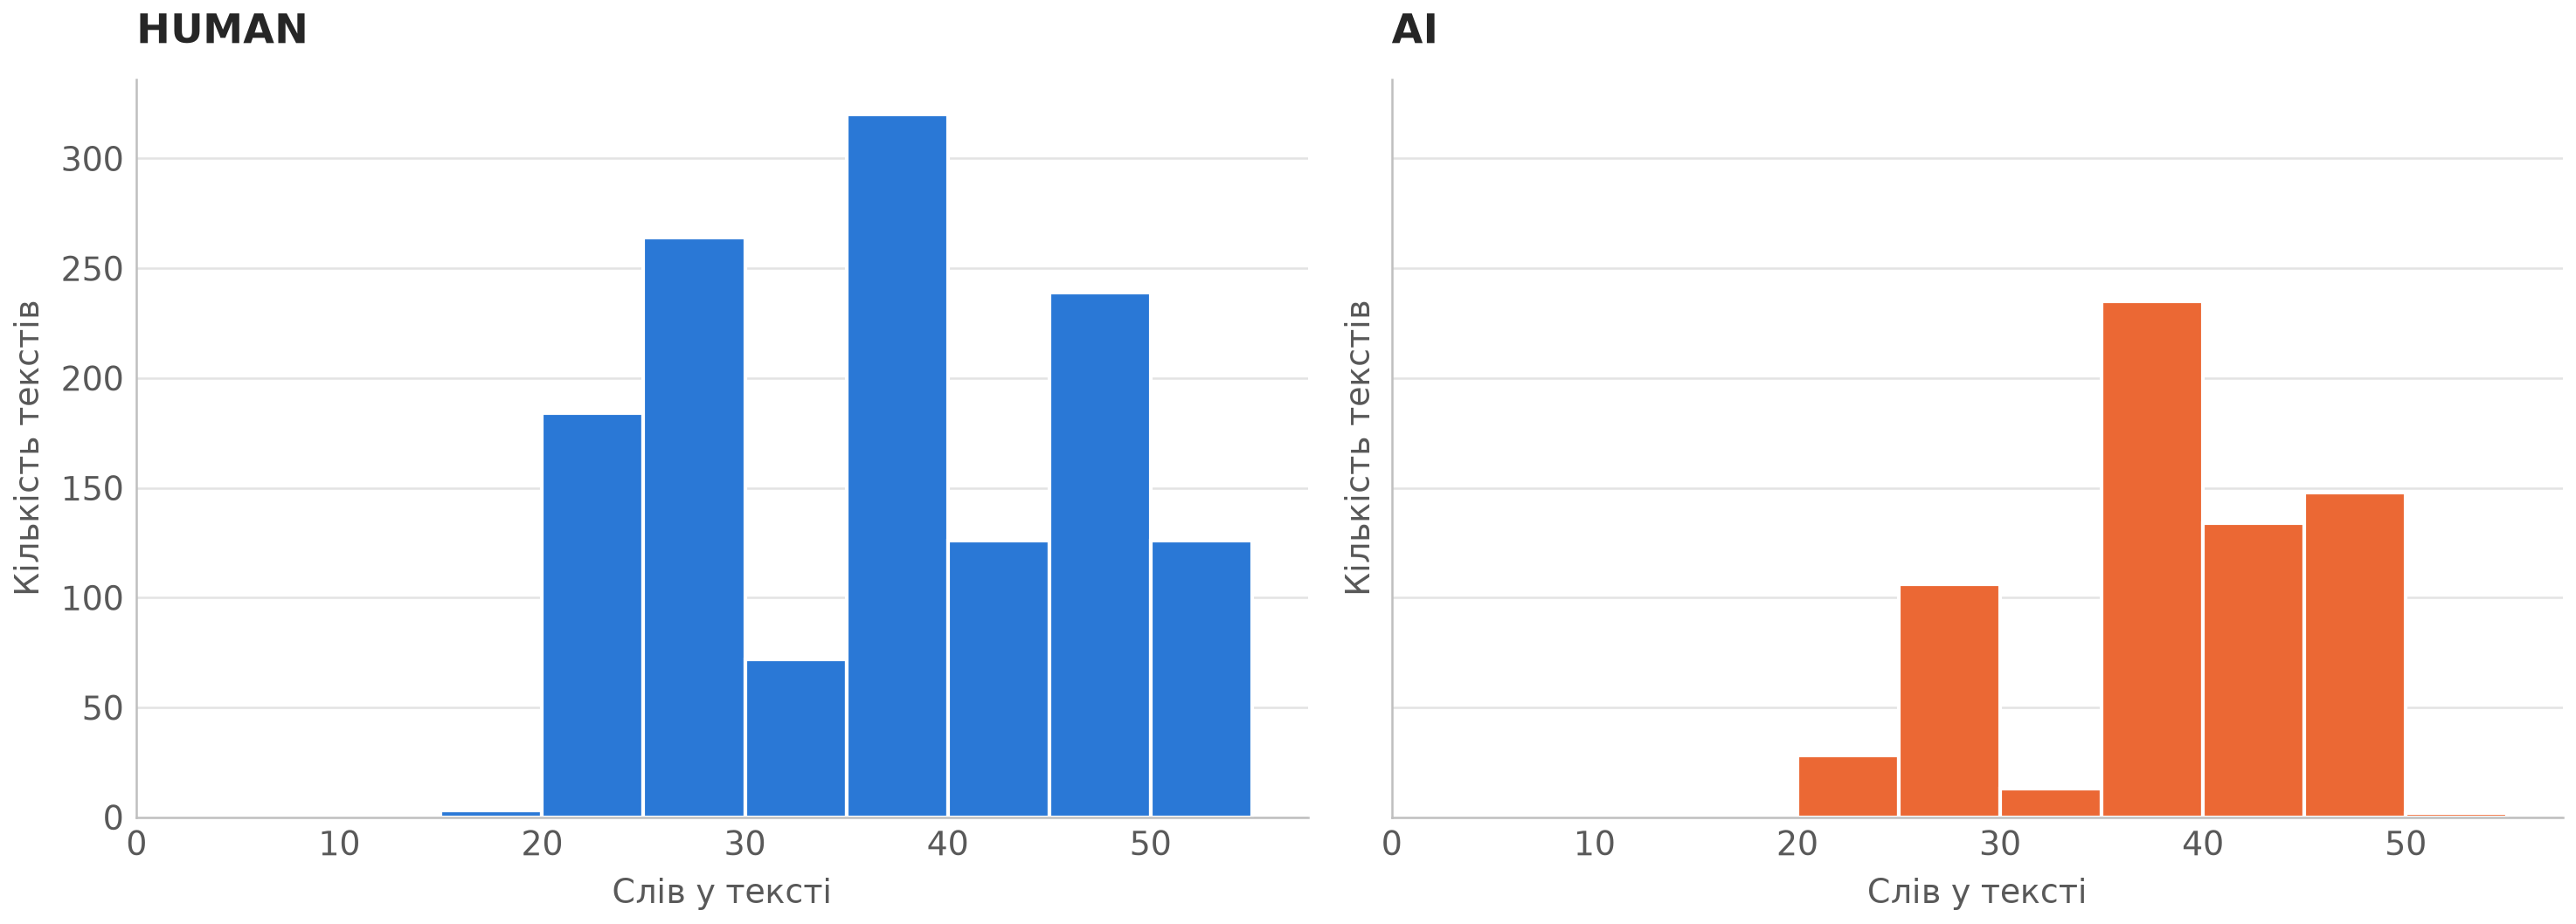

**Рисунок 1 — Розподіли кількості слів до очищення.**

In [3]:
CSV_GZIP_BASE64 = '...'
SOURCE = {'title': 'AI vs Human Text Classification Dataset 2026', 'page_url': 'https://www.kaggle.com/datasets/alitaqishah/ai-vs-human-text-classification-dataset-2026', 'download_url': 'https://www.kaggle.com/api/v1/datasets/download/alitaqishah/ai-vs-human-text-classification-dataset-2026', 'accessed_utc': '2026-11-03T13:56:20.919465+00:00', 'csv': 'ai_vs_human_text_2026.csv', 'bytes': 696551, 'sha256': '9150ddbb4a90a21f7825b8400adeefcc4dd1fcb06241121bac6ef385b3a48c3a'}
raw_bytes = gzip.decompress(base64.b64decode(CSV_GZIP_BASE64))
assert hashlib.sha256(raw_bytes).hexdigest() == SOURCE['sha256']
raw = pd.read_csv(io.BytesIO(raw_bytes))
assert set(raw['label']) == {'human', 'ai'}
print(json.dumps(SOURCE, ensure_ascii=False, indent=2))
print('Розмір CSV:', raw.shape)
display(raw.head(3))
raw['n_words'] = raw['text_content'].fillna('').str.split().str.len()
eda = raw.groupby('label')['n_words'].agg(['count','min','median','mean','max']).reset_index()
table(eda, 'Таблиця 1 — Класи й довжини вихідних текстів, слів', 2)
eda.to_csv(OUT/'eda_lengths.csv', index=False)
print('Пропуски за полями:', raw.isna().sum().to_dict())
print('Дослівні дублікати text_content:', int(raw.text_content.duplicated().sum()))
print('Тексти коротші за 5 слів:', int((raw.n_words < 5).sum()))
print('Розбіжності з полем word_count:', int((raw.n_words != raw.word_count).sum()))
print('Походження записів за метаданими:')
display(raw.groupby(['label','generation_method']).size().rename('count').reset_index())
fig, axes = plt.subplots(1,2,figsize=(10,3.7),sharex=True,sharey=True)
bins = np.arange(0, int(raw.n_words.max()) + 6, 5)
for ax, (label, color) in zip(axes, [('human', COLORS[0]), ('ai', COLORS[1])]):
    ax.hist(raw.loc[raw.label.eq(label),'n_words'], bins=bins, color=color, edgecolor='white')
    ax.set(title=label.upper(), xlabel='Слів у тексті', ylabel='Кількість текстів')
    ax.set_xlim(left=0)
show_figure(fig, 'figure_01_lengths.png')
display(Markdown('**Рисунок 1 — Розподіли кількості слів до очищення.**'))

### Очищення та spaCy
Вилучаємо порожні/безміткові тексти, записи коротші за 5 слів (недостатній контекст) і дублікати після приведення пробілів та регістру. Якщо однакові тексти мають суперечливі мітки, вилучаємо всю таку групу. Після spaCy також вилучаємо порожні послідовності та однакові послідовності лем; конфліктні групи лем вилучаються цілком. Рішення ґрунтується на змісті, а не на результаті класифікації. Воно зменшує вибірку, зате не дозволяє тому самому обробленому тексту потрапити в обидві частини.

`nlp.pipe(batch_size=64, n_process=1)` виконує лематизацію моделлю `en_core_web_sm`; залишаємо лише `is_alpha` і не `is_stop`, леми переводимо в нижній регістр. Вимикаємо parser та NER, які не потрібні для цієї задачі. spaCy-модель готова заздалегідь і на цьому датасеті не донавчається. У таблиці 2 наведено журнал очищення; це дає змогу простежити всі вилучення.

In [4]:
audit=[]
def record(step, frame):
    audit.append({'Етап':step,'Залишилось':len(frame)})
df = raw.copy()
record('Вхідний CSV',df)
df = df.dropna(subset=['text_content','label']).copy()
df['text_key'] = df.text_content.str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
df = df.loc[df.text_key.ne('') & df.n_words.ge(5)].copy()
record('Валідний текст і ≥5 слів',df)
conflicts = df.groupby('text_key').label.nunique()
conflict_keys = set(conflicts[conflicts.gt(1)].index)
df = df.loc[~df.text_key.isin(conflict_keys)].drop_duplicates('text_key').copy()
record('Без конфліктів і нормалізованих повторів',df)
nlp = spacy.load('en_core_web_sm', disable=['parser','ner'])
df['tokens'] = [[t.lemma_.lower() for t in doc if t.is_alpha and not t.is_stop]
    for doc in nlp.pipe(df.text_content.tolist(), batch_size=64, n_process=1)]
df['lemma_key'] = df.tokens.map(tuple)
df = df.loc[df.tokens.str.len().gt(0)].copy()
record('Непорожні леми',df)
lemma_conflicts = df.groupby('lemma_key').label.nunique()
bad_lemmas = set(lemma_conflicts[lemma_conflicts.gt(1)].index)
df = df.loc[~df.lemma_key.isin(bad_lemmas)].drop_duplicates('lemma_key').reset_index(drop=True)
df['y'] = df.label.map({'human':0,'ai':1}).astype(int)
record('Без конфліктів і повторів лем',df)
audit_frame = pd.DataFrame(audit)
audit_frame['Вилучено на етапі'] = audit_frame['Залишилось'].shift(1).fillna(len(raw)).astype(int) - audit_frame['Залишилось']
table(audit_frame,'Таблиця 2 — Журнал очищення',0)
audit_frame.to_csv(OUT/'cleaning.csv',index=False)
print('Конфліктних текстових/лематизованих груп:',len(conflict_keys),len(bad_lemmas))
print('Класи після очищення:',df.label.value_counts().to_dict())
print('Приклад лематизації:', df.tokens.iloc[0])
assert df.lemma_key.is_unique and df.text_key.is_unique

**Таблиця 2 — Журнал очищення**

| Етап                                     |   Залишилось |   Вилучено на етапі |
|:-----------------------------------------|-------------:|--------------------:|
| Вхідний CSV                              |         2000 |                   0 |
| Валідний текст і ≥5 слів                 |         2000 |                   0 |
| Без конфліктів і нормалізованих повторів |          866 |                1134 |
| Непорожні леми                           |          866 |                   0 |
| Без конфліктів і повторів лем            |          866 |                   0 |

Конфліктних текстових/лематизованих груп: 0 0
Класи після очищення: {'human': 479, 'ai': 387}
Приклад лематизації: ['talk', 'gene', 'edit', 'ethic', 'sec', 'feel', 'like', 'people', 'completely', 'miss', 'point', 'big', 'realize']


### Єдиний поділ і навчання FastText
У таблиці 3 показано один стратифікований поділ 80/20 з `random_state=42`. Далі індекси не змінюються. FastText і словник/IDF TF-IDF навчаються **виключно на train**. Цільові мітки не використовуються для навчання представлень. Тестові слова можуть отримувати субслівні FastText-вектори, але не оновлюють модель.

FastText: `vector_size=100, window=5, min_count=2, sg=1, seed=42, workers=1, epochs=5`; решта параметрів — стандартні gensim (зокрема `min_n=3`, `max_n=6`, `bucket=2000000`). Відтворювана хеш-функція задана нижче. Жодне масштабування чи додаткова нормалізація векторів не застосовується, щоб ізолювати зміну агрегації та зберегти параметри методички.

In [5]:
train_idx, test_idx = train_test_split(np.arange(len(df)), test_size=0.2,
    random_state=SEED, stratify=df.y)
train = df.iloc[train_idx].copy()
test = df.iloc[test_idx].copy()
assert set(train.text_key).isdisjoint(test.text_key)
assert set(train.lemma_key).isdisjoint(test.lemma_key)
assert set(train.text_id).isdisjoint(test.text_id)
y_train, y_test = train.y.to_numpy(), test.y.to_numpy()
split = pd.DataFrame([{'Частина':name,'Human':int((part.y==0).sum()),
    'AI':int((part.y==1).sum()),'Усього':len(part)} for name,part in [('train',train),('test',test)]])
table(split,'Таблиця 3 — Спільний поділ даних',0)
pd.concat([train[['text_id','label']].assign(split='train'),
           test[['text_id','label']].assign(split='test')]).to_csv(OUT/'split.csv',index=False)
def stable_hash(word):
    return int.from_bytes(hashlib.md5(word.encode('utf-8')).digest()[:8], 'little')
ft = FastText(sentences=train.tokens.tolist(), vector_size=100, window=5,
    min_count=2, sg=1, workers=1, seed=SEED, epochs=5, hashfxn=stable_hash)
print('Навчальних документів FastText:', ft.corpus_count)
print('Слів у словнику FastText:', len(ft.wv.key_to_index))
assert ft.corpus_count == len(train)

**Таблиця 3 — Спільний поділ даних**

| Частина   |   Human |   AI |   Усього |
|:----------|--------:|-----:|---------:|
| train     |     383 |  309 |      692 |
| test      |      96 |   78 |      174 |

Навчальних документів FastText: 692
Слів у словнику FastText: 508


### Два представлення документа
Для послідовності лем $w_1,\ldots,w_m$:

$$v_d^{mean}=\frac1m\sum_{i=1}^m v_{w_i},\qquad
v_d^{tfidf}=\frac{\sum_{i=1}^m a(w_i,d)v_{w_i}}{\sum_{i=1}^m a(w_i,d)},\quad
a(t,d)=tf(t,d)\log\frac{N_{train}}{df_{train}(t)}.$$

Використовуємо сирі частоти термінів та IDF без згладжування, як у теоретичній формулі методички. `TfidfVectorizer(smooth_idf=False, norm=None)` додає до IDF одиницю; віднімаємо її після `fit`, щоб отримати саме $\log(N/df)$. Токенізатор зберігає однолітерні леми й не виконує повторне очищення.

Як у циклі прикладу на с. 4, підсумовуємо **за входженнями токенів**: кожне повторення отримує TF-IDF вагу відповідного терміна. Тому сумарний внесок повторюваного терміна пропорційний $tf^2\cdot idf$; це явна властивість наведеної реалізації, відмінна від підсумовування лише за унікальними термінами. В обох способах зберігаємо цей порядок токенів. Невідомі для TF-IDF терміни мають нульову вагу, а FastText може обчислювати їхні вектори за субсловами. Порожній документ або нульова сума ваг дають нульовий вектор, без NaN.

In [6]:
tfidf = TfidfVectorizer(analyzer=lambda x:x, lowercase=False, norm=None,
                        smooth_idf=False, sublinear_tf=False)
tfidf.fit(train.tokens.tolist())
tfidf.idf_ = tfidf.idf_ - 1.0  # точний log(N_train / df_train)
T_train = tfidf.transform(train.tokens.tolist())
T_test = tfidf.transform(test.tokens.tolist())
vocab = tfidf.vocabulary_
def mean_pooling(tokens):
    vectors = [ft.wv[t] for t in tokens if t in ft.wv]
    return np.mean(vectors,axis=0) if vectors else np.zeros(ft.vector_size)
def weighted_pooling(tokens, row):
    scores = dict(zip(row.indices, row.data))
    vectors, weights = [], []
    for t in tokens:
        weight = scores.get(vocab.get(t,-1),0.0)
        if t in ft.wv and weight > 0:
            vectors.append(ft.wv[t]); weights.append(weight)
    total = np.sum(weights)
    if not vectors or total <= 0:
        return np.zeros(ft.vector_size)
    return np.average(np.asarray(vectors),axis=0,weights=np.asarray(weights)/total)
def represent(part, matrix, weighted=False):
    return np.vstack([weighted_pooling(tok,matrix.getrow(i)) if weighted else mean_pooling(tok)
                     for i,tok in enumerate(part.tokens)])
representations = {
    'Mean Pooling':(represent(train,T_train),represent(test,T_test)),
    'TF-IDF Weighted':(represent(train,T_train,True),represent(test,T_test,True))}
assert np.all(mean_pooling([])==0)
assert np.all(weighted_pooling([],T_test.getrow(0))==0)
assert np.all(weighted_pooling(['unknownwordxyz'], T_test.getrow(0)*0)==0)
for name,(xtr,xte) in representations.items():
    assert xtr.shape==(len(train),100) and xte.shape==(len(test),100)
    assert np.isfinite(xtr).all() and np.isfinite(xte).all()
    print(name, 'train/test:', xtr.shape,xte.shape,'нульових test:',int((np.linalg.norm(xte,axis=1)==0).sum()))
assert set(vocab) == set(t for ts in train.tokens for t in ts)

Mean Pooling train/test: (692, 100) (174, 100) нульових test: 0
TF-IDF Weighted train/test: (692, 100) (174, 100) нульових test: 0


### Шість класифікаційних експериментів
У таблиці 4 наведені чотири метрики на одному тесті. Позитивний клас ROC-AUC — **AI (1)**, оцінка береться з `predict_proba` за індексом класу 1. F1 усереднюється за класами (`macro`), Balanced Accuracy — середнє повнот класів. Параметри класифікаторів відповідають методичці, використано стандартне `C=1` та `gamma='scale'` для SVM. Основний критерій порівняння — F1 macro; за нічиєї — ROC-AUC.

In [7]:
rows, predictions, fitted = [], {}, {}
for representation,(xtr,xte) in representations.items():
    classifiers = {
        'SVM (RBF)':SVC(kernel='rbf',probability=True,random_state=SEED),
        'Logistic Regression':LogisticRegression(max_iter=1000,random_state=SEED),
        'KNN (k=5)':KNeighborsClassifier(n_neighbors=5)}
    for name,clf in classifiers.items():
        clf.fit(xtr,y_train)
        pred = clf.predict(xte)
        score = clf.predict_proba(xte)[:,list(clf.classes_).index(1)]
        rows.append({'Representation':representation,'Classifier':name,
            'F1 macro':f1_score(y_test,pred,average='macro'),
            'Accuracy':accuracy_score(y_test,pred),
            'Balanced Accuracy':balanced_accuracy_score(y_test,pred),
            'ROC-AUC':roc_auc_score(y_test,score)})
        predictions[(representation,name)] = (pred,score)
        fitted[(representation,name)] = clf
results = pd.DataFrame(rows)
table(results,'Таблиця 4 — Якість шести моделей на спільному тесті')
results.to_csv(OUT/'metrics.csv',index=False)
pred_frame = test[['text_id','label']].reset_index(drop=True).copy()
for (rep,name),(pred,score) in predictions.items():
    pred_frame[f'{rep} | {name} | prediction'] = pred
    pred_frame[f'{rep} | {name} | P(AI)'] = score
pred_frame.to_csv(OUT/'predictions.csv',index=False)

/work/scratch/ml_env/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/work/scratch/ml_env/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


**Таблиця 4 — Якість шести моделей на спільному тесті**

| Representation   | Classifier          |   F1 macro |   Accuracy |   Balanced Accuracy |   ROC-AUC |
|:-----------------|:--------------------|-----------:|-----------:|--------------------:|----------:|
| Mean Pooling     | SVM (RBF)           |     0.8793 |     0.8793 |              0.8882 |    0.9629 |
| Mean Pooling     | Logistic Regression |     0.7570 |     0.7586 |              0.7584 |    0.8480 |
| Mean Pooling     | KNN (k=5)           |     1.0000 |     1.0000 |              1.0000 |    1.0000 |
| TF-IDF Weighted  | SVM (RBF)           |     0.8793 |     0.8793 |              0.8906 |    0.9692 |
| TF-IDF Weighted  | Logistic Regression |     0.7737 |     0.7759 |              0.7740 |    0.8582 |
| TF-IDF Weighted  | KNN (k=5)           |     1.0000 |     1.0000 |              1.0000 |    1.0000 |

На рисунку 2 показано помилки Mean Pooling + SVM, на рисунку 3 — Mean Pooling + Logistic Regression, на рисунку 4 — Mean Pooling + KNN. На рисунку 5 наведено TF-IDF Weighted + SVM, на рисунку 6 — TF-IDF Weighted + Logistic Regression, на рисунку 7 — TF-IDF Weighted + KNN. Рядки — істинний клас, стовпці — прогноз; порядок класів і шкала кількості об'єктів однакові.

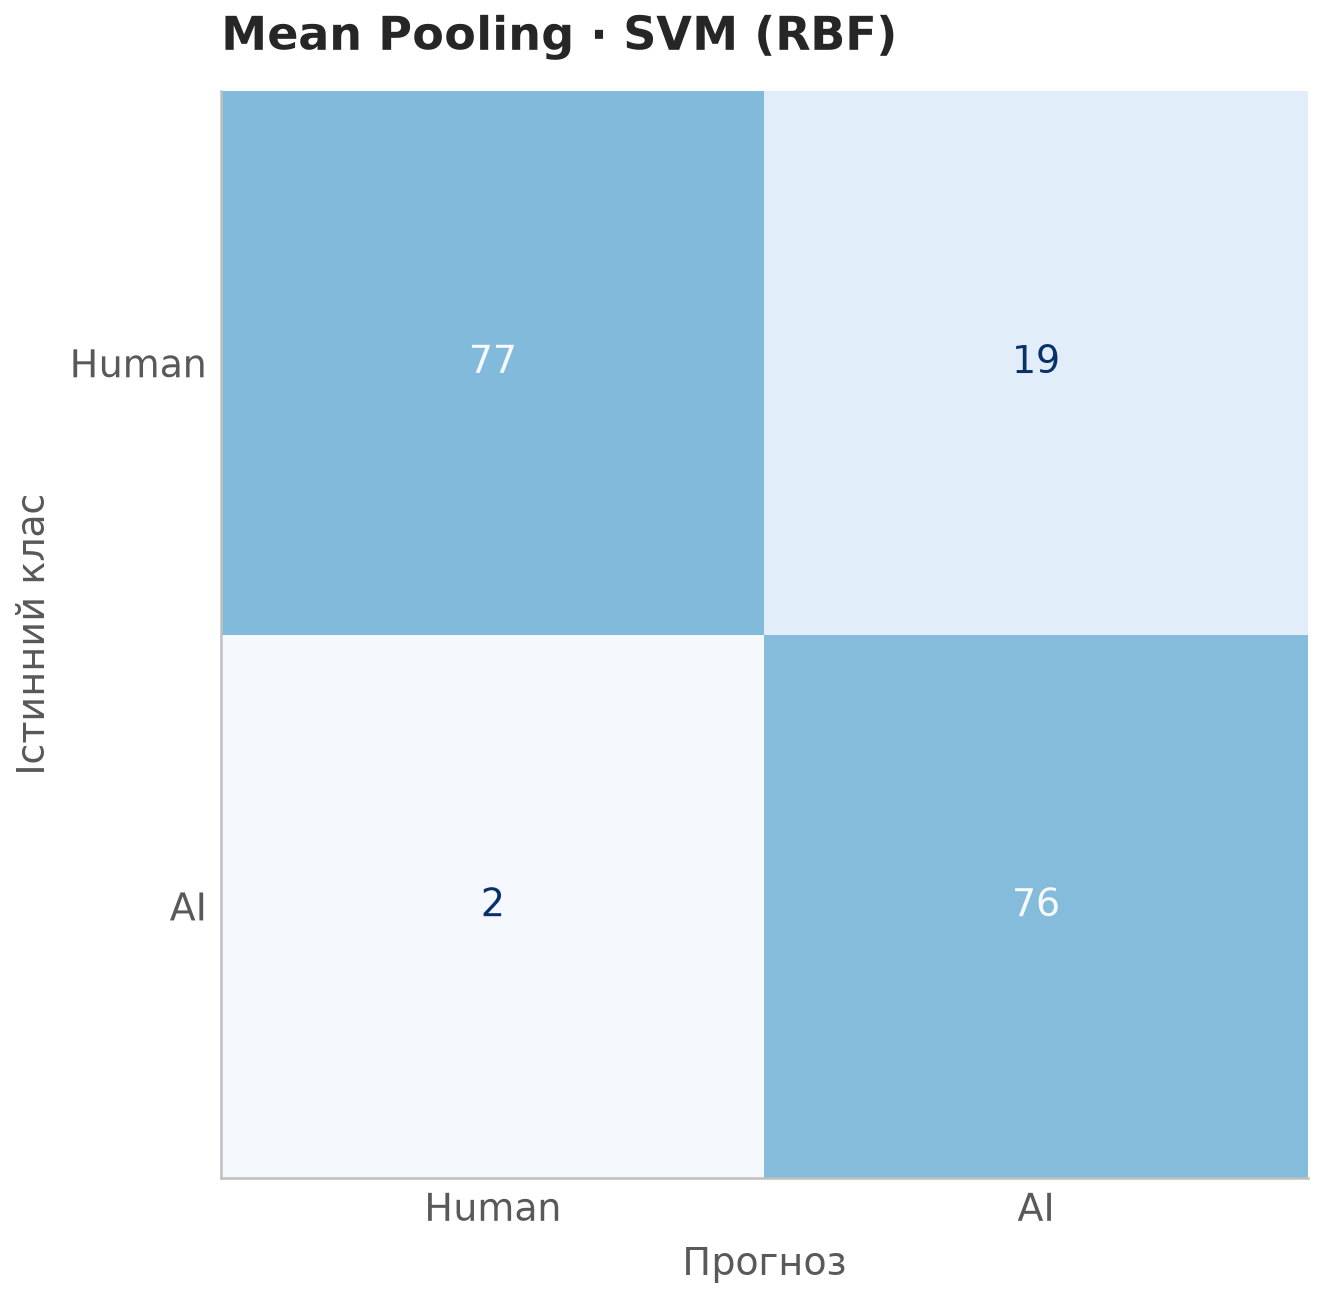

**Рисунок 2 — Матриця помилок: Mean Pooling, SVM (RBF).**

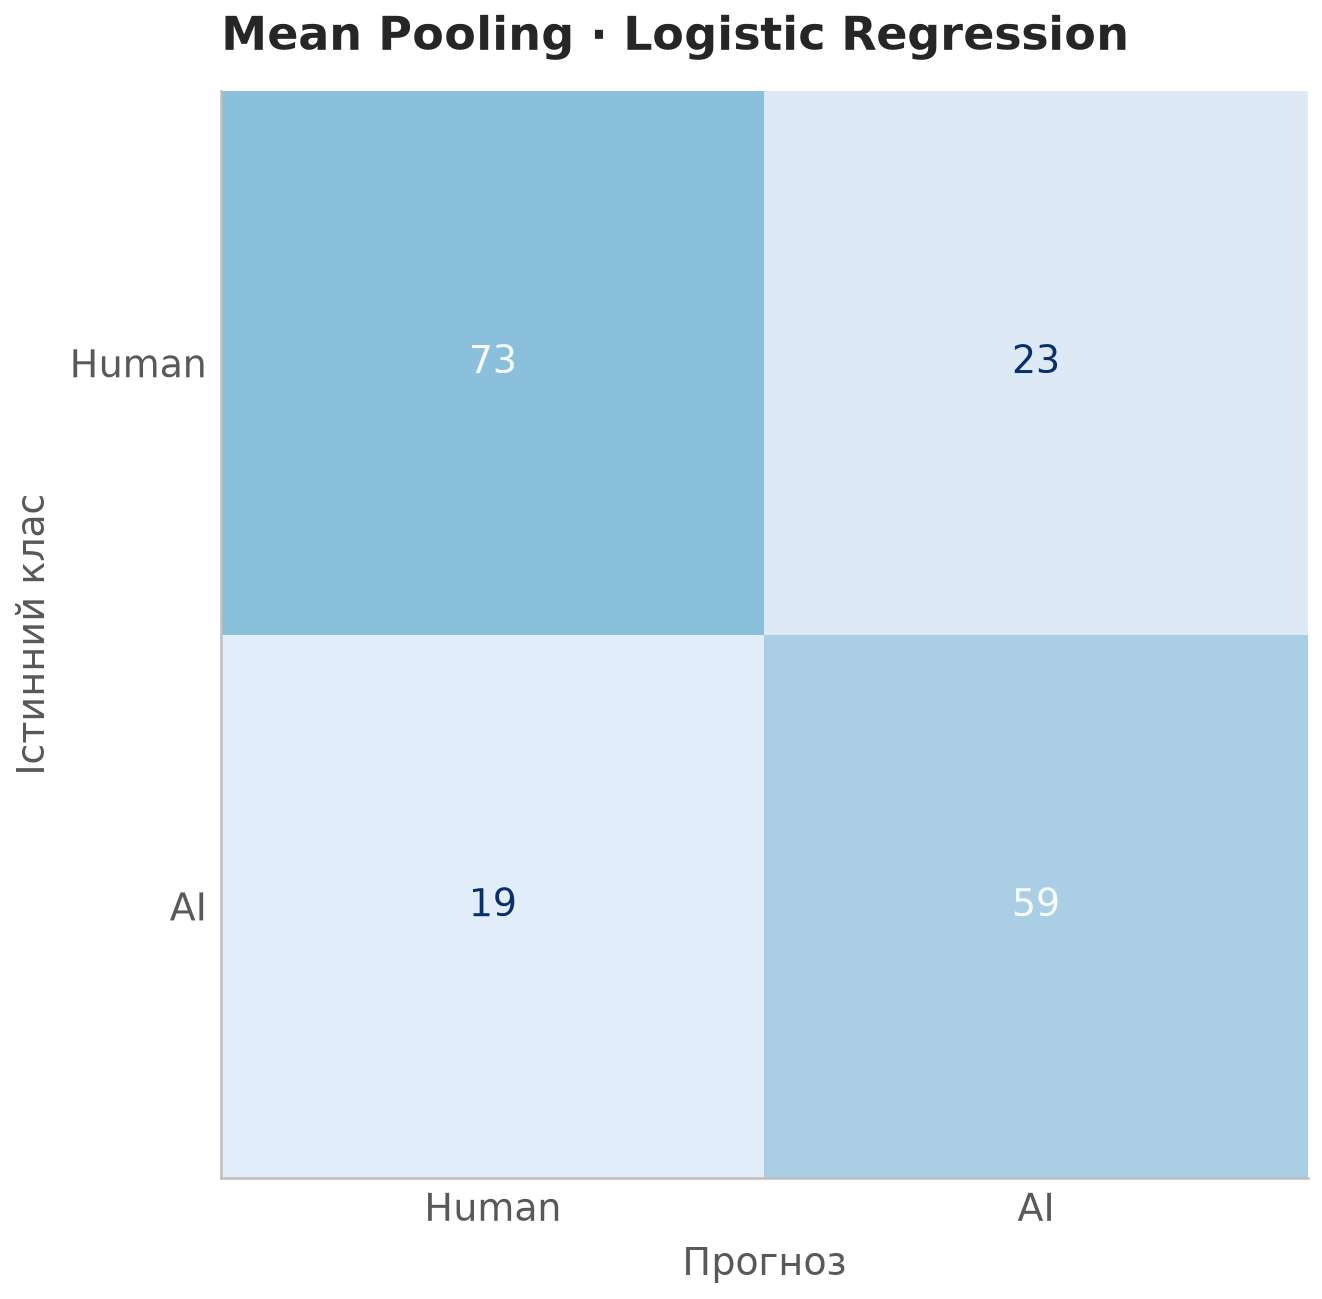

**Рисунок 3 — Матриця помилок: Mean Pooling, Logistic Regression.**

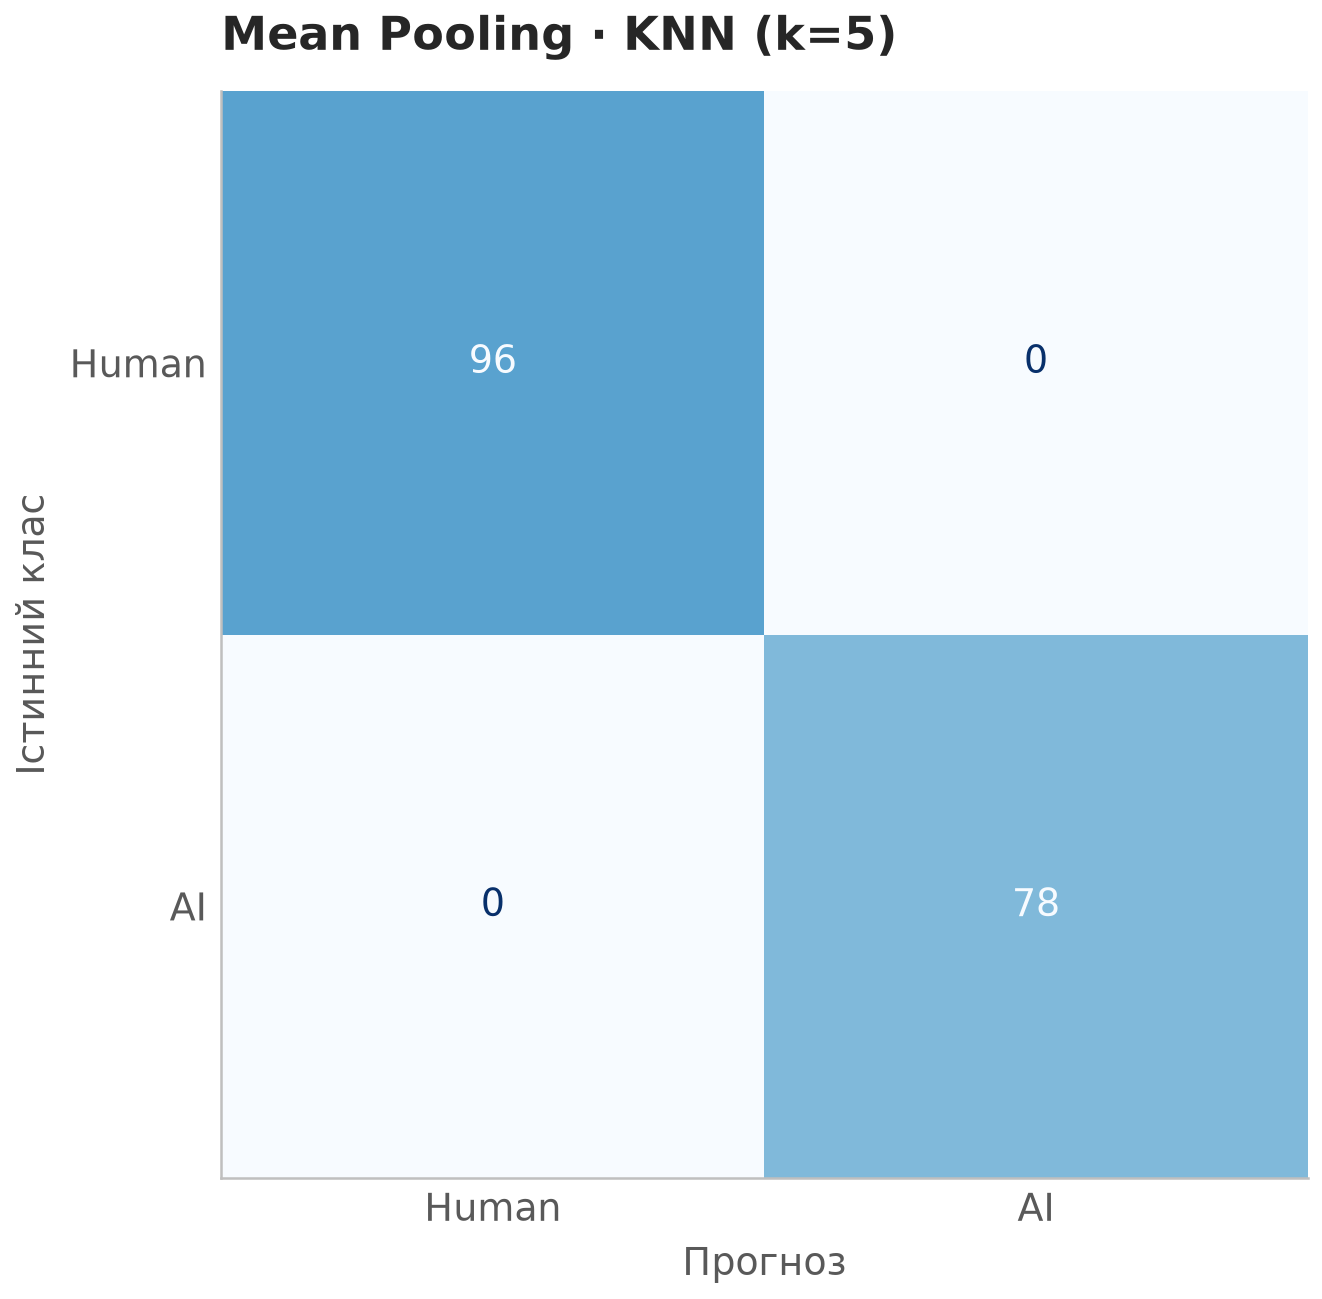

**Рисунок 4 — Матриця помилок: Mean Pooling, KNN (k=5).**

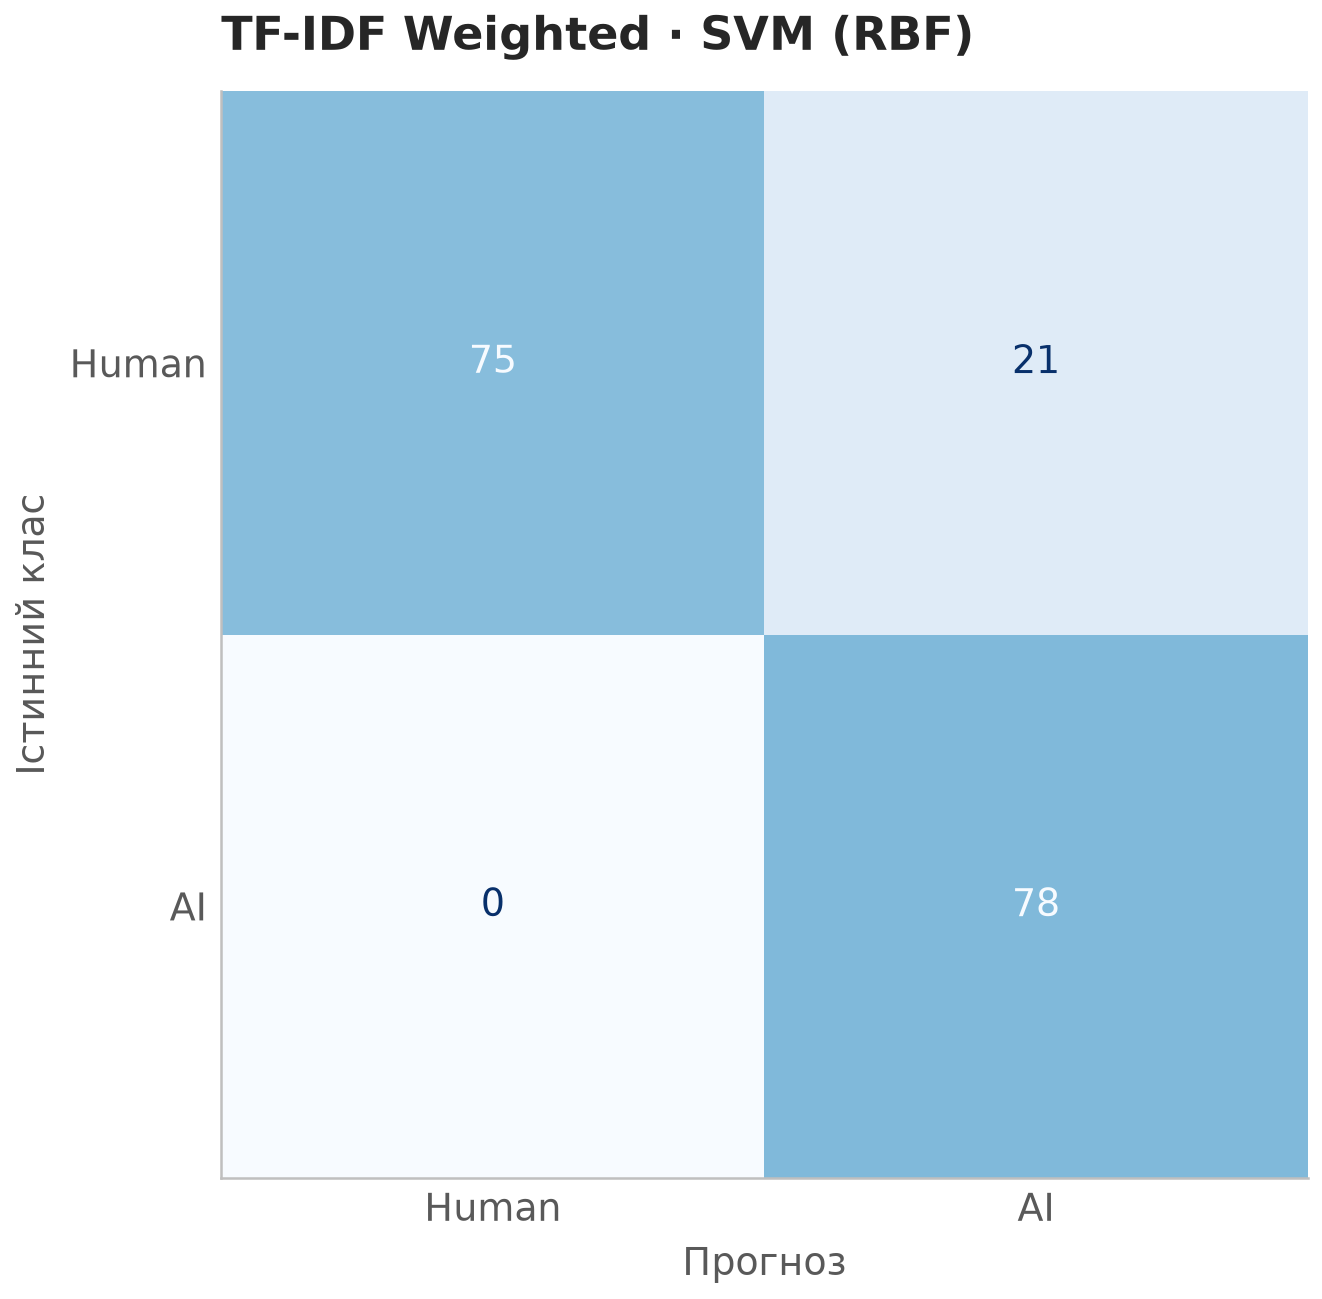

**Рисунок 5 — Матриця помилок: TF-IDF Weighted, SVM (RBF).**

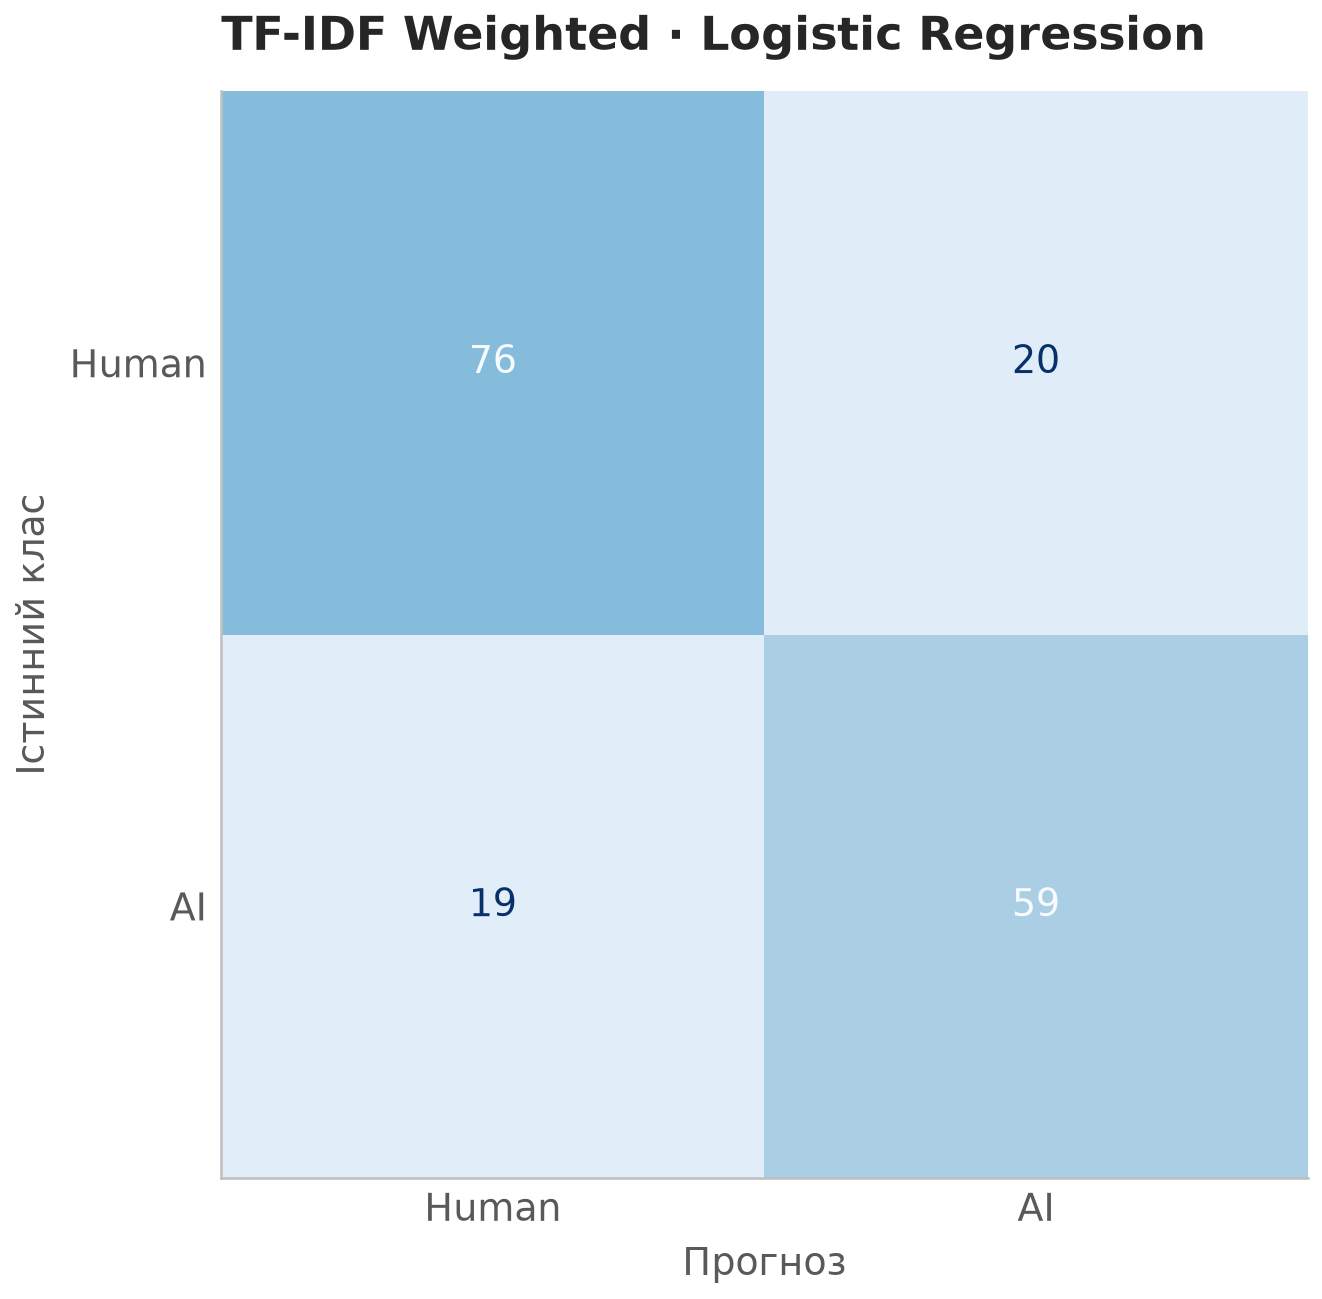

**Рисунок 6 — Матриця помилок: TF-IDF Weighted, Logistic Regression.**

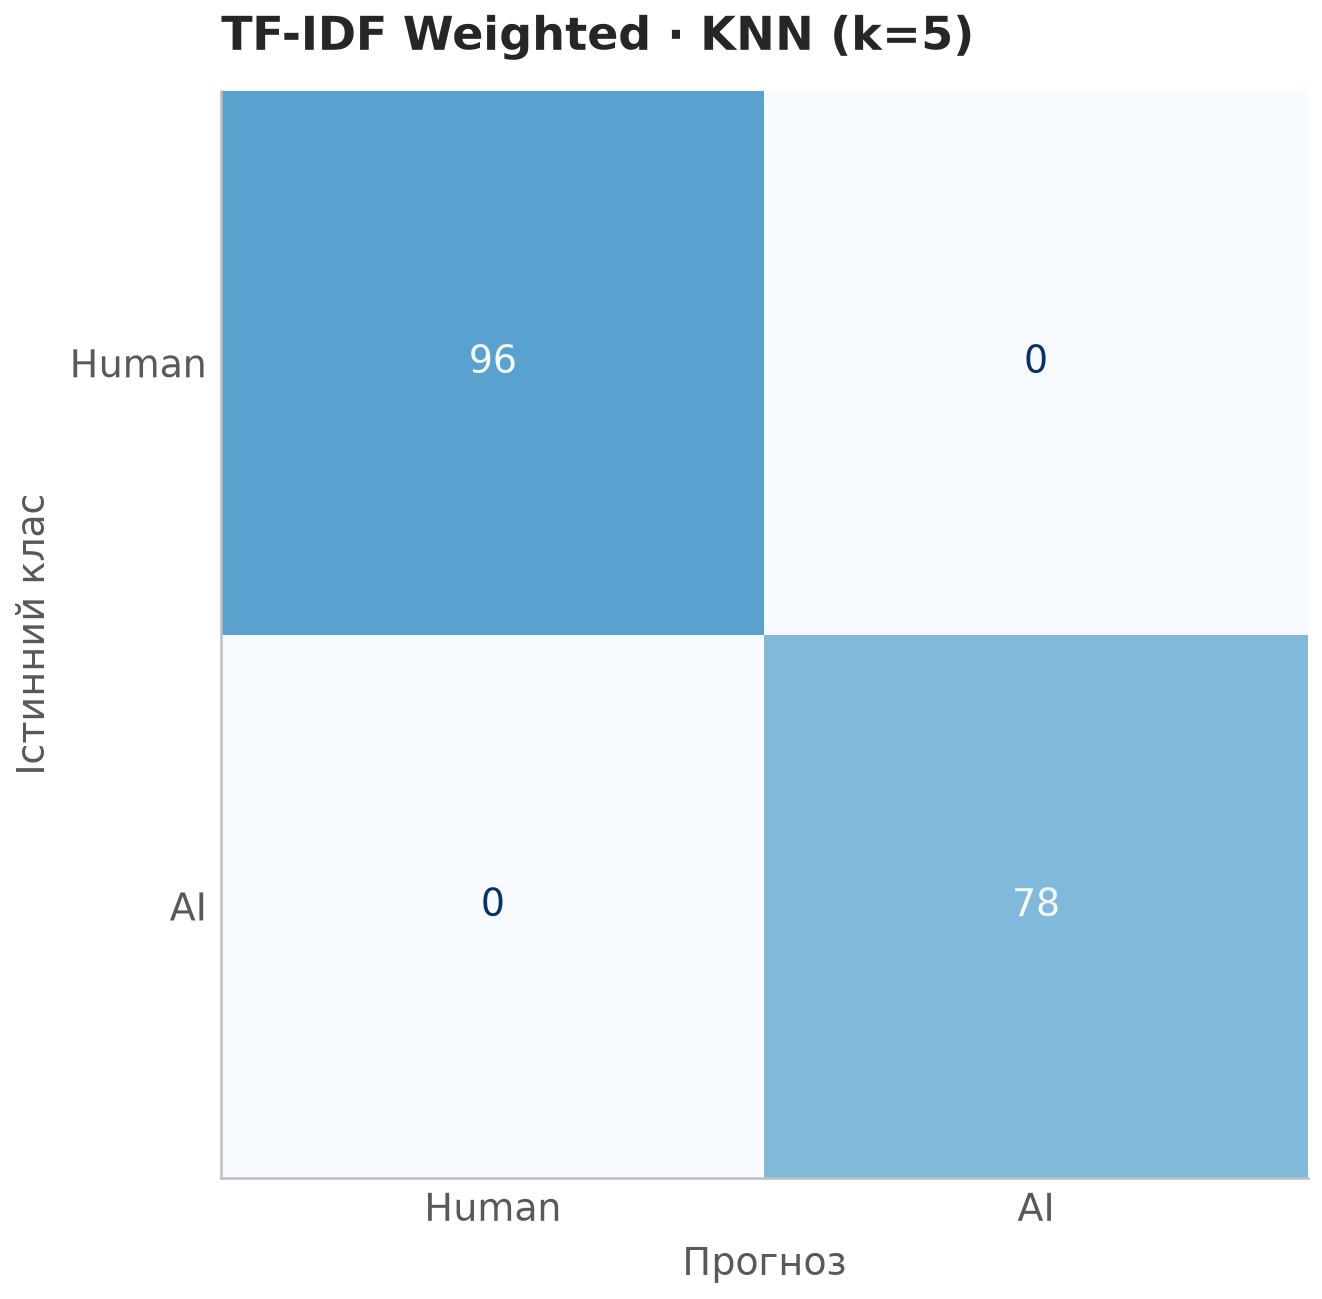

**Рисунок 7 — Матриця помилок: TF-IDF Weighted, KNN (k=5).**

625

In [8]:
matrices = {f'{rep} | {name}':confusion_matrix(y_test,pred,labels=[0,1]).tolist()
            for (rep,name),(pred,score) in predictions.items()}
for number,((rep,name),(pred,score)) in enumerate(predictions.items(),start=2):
    fig,ax = plt.subplots(figsize=(6.3,4.5))
    cm = confusion_matrix(y_test,pred,labels=[0,1])
    disp = ConfusionMatrixDisplay(cm,display_labels=['Human','AI'])
    disp.plot(ax=ax,cmap='Blues',colorbar=False,values_format='d',im_kw={'vmin':0,'vmax':len(test)})
    ax.grid(False)
    ax.set(xlabel='Прогноз',ylabel='Істинний клас',title=f'{rep} · {name}')
    show_figure(fig,f'figure_{number:02d}_confusion.png')
    display(Markdown(f'**Рисунок {number} — Матриця помилок: {rep}, {name}.**'))
    assert cm.sum() == len(test)
(OUT/'confusion_matrices.json').write_text(json.dumps(matrices,indent=2),encoding='utf-8')

### Геометрія та t-SNE
На рисунку 8 наведено t-SNE Mean Pooling, на рисунку 9 — t-SNE TF-IDF Weighted. Використано **всі ті самі тестові об'єкти**, в тому самому порядку, Human — синій, AI — помаранчевий. Параметри: `n_components=2, perplexity=30, init='pca', learning_rate='auto', max_iter=1000, metric='euclidean', random_state=42`. Проєкції будуються окремо, тому їхні осі, поворот і абсолютні відстані не порівнюються безпосередньо. Це візуалізація тесту після оцінювання, а не ознаки для навчання чи добору моделі.

У таблиці 5 порівнюємо silhouette за істинними класами у вихідних 100D-векторах та в 2D. Додатково рахуємо середній радіус усередині класу, відстань центроїдів і їхнє відношення (більше — краще відокремлення щодо розсіювання), а також коефіцієнт варіації всіх попарних відстаней. Для KNN вимірюємо частку 5 найближчих тестових сусідів з тією самою міткою. Ці діагностики описують тест постфактум і не налаштовують моделі. 2D silhouette може спотворювати справжню геометрію; основні висновки про якість спираються на таблицю 4.

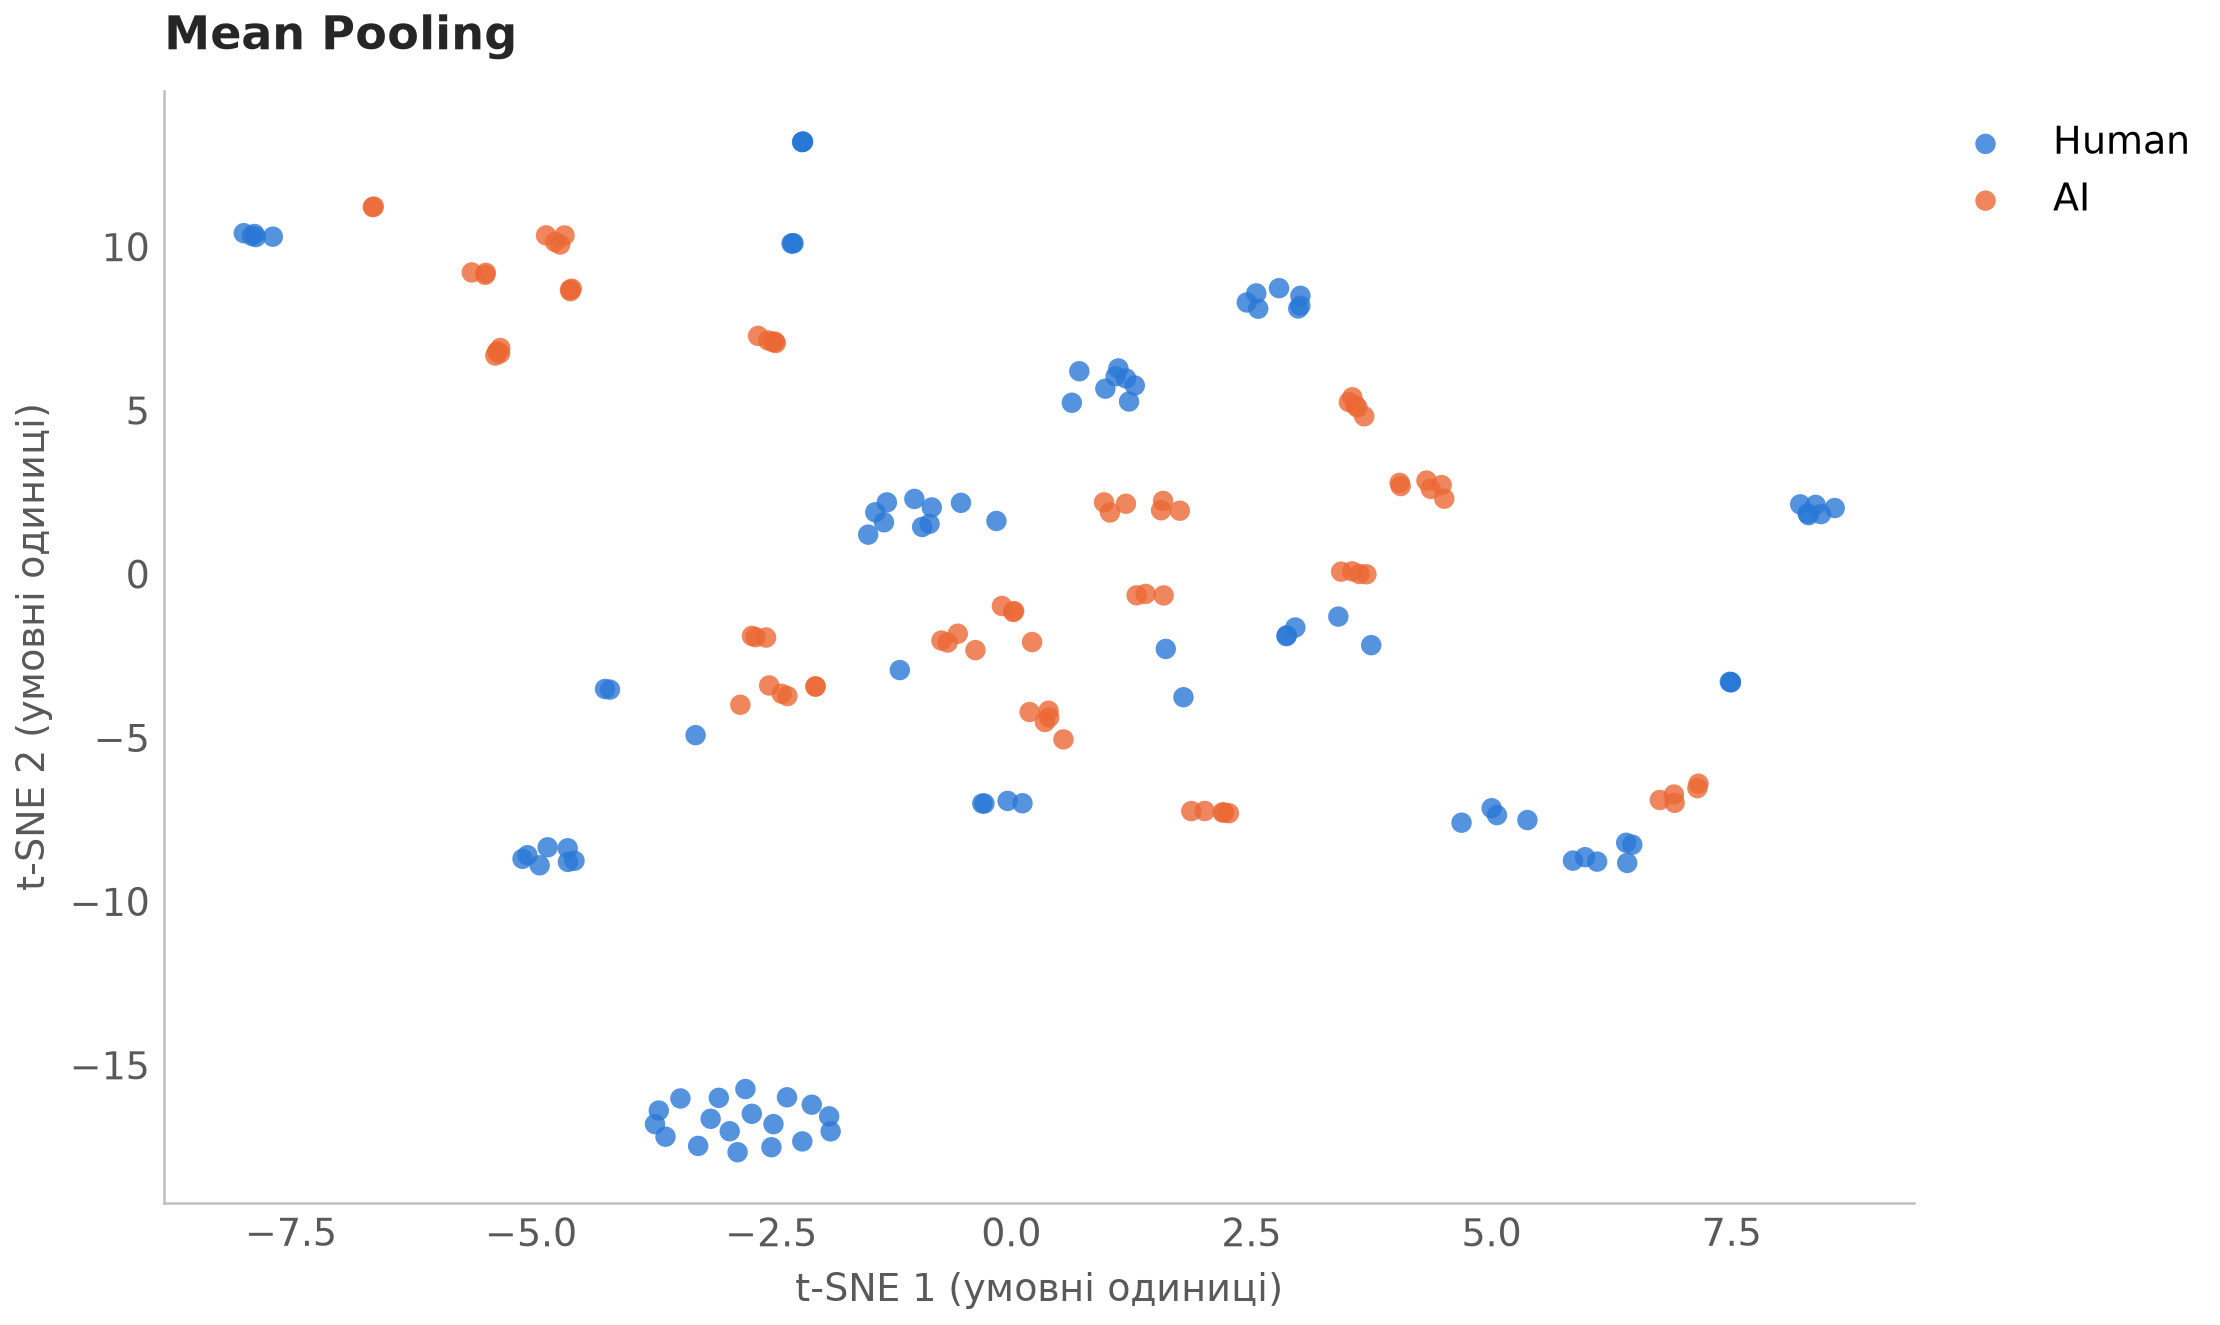

**Рисунок 8 — t-SNE: Mean Pooling, спільна тестова вибірка.**

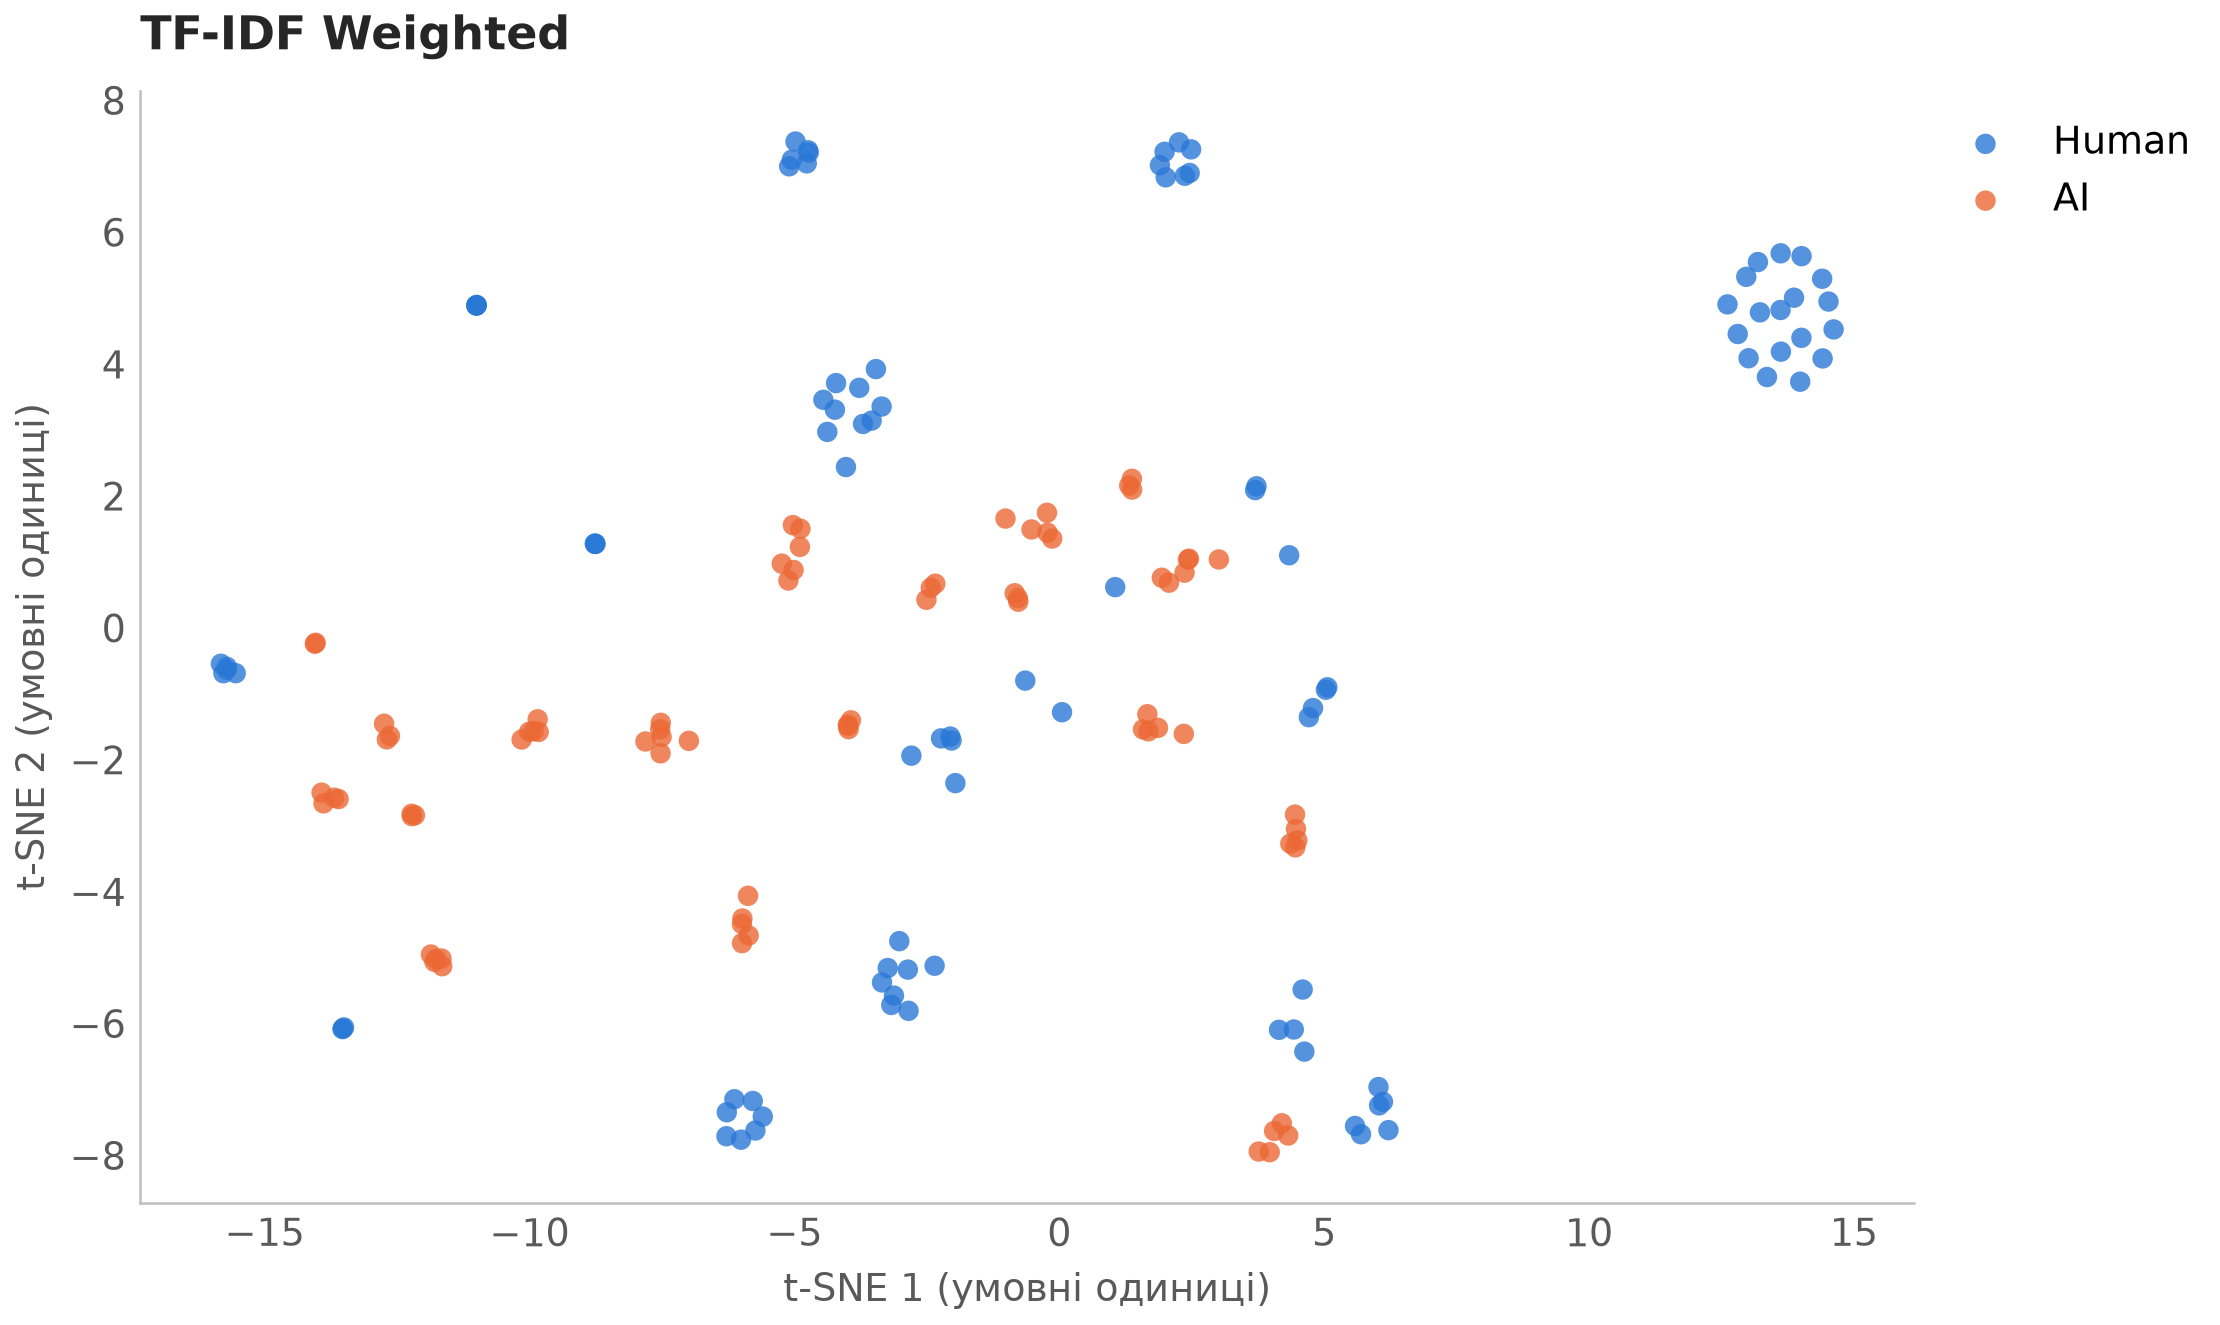

**Рисунок 9 — t-SNE: TF-IDF Weighted, спільна тестова вибірка.**

**Таблиця 5 — Геометричні діагностики спільного тесту**

| Representation   |   Silhouette 100D |   Silhouette 2D |   Mean radius |   Centroid distance |   Separation / radius |   Distance CV |   Neighbor agreement |
|:-----------------|------------------:|----------------:|--------------:|--------------------:|----------------------:|--------------:|---------------------:|
| Mean Pooling     |            0.0645 |          0.0471 |        0.6846 |              0.3951 |                0.5772 |        0.4451 |               0.8966 |
| TF-IDF Weighted  |            0.0670 |          0.0594 |        0.6684 |              0.3842 |                0.5747 |        0.4352 |               0.8782 |

In [9]:
projections, geometry_rows = {}, []
for number,(name,(xtr,xte)) in enumerate(representations.items(),start=8):
    assert len(xte)==len(test) and len(test)>30
    z = TSNE(n_components=2,perplexity=30,init='pca',learning_rate='auto',
        max_iter=1000,metric='euclidean',random_state=SEED).fit_transform(xte)
    projections[name]=z
    fig,ax=plt.subplots(figsize=(7.6,4.6))
    for cls in [0,1]:
        ax.scatter(z[y_test==cls,0],z[y_test==cls,1],c=COLORS[cls],
            label=NAMES[cls],s=24,alpha=.8,edgecolors='none')
    ax.set(title=name,xlabel='t-SNE 1 (умовні одиниці)',ylabel='t-SNE 2 (умовні одиниці)')
    ax.legend(loc='upper left',bbox_to_anchor=(1,1))
    ax.grid(False)
    show_figure(fig,f'figure_{number:02d}_tsne.png')
    display(Markdown(f'**Рисунок {number} — t-SNE: {name}, спільна тестова вибірка.**'))
    centers=np.vstack([xte[y_test==c].mean(axis=0) for c in [0,1]])
    radius=np.mean([np.linalg.norm(xte[i]-centers[y_test[i]]) for i in range(len(test))])
    separation=np.linalg.norm(centers[1]-centers[0])
    distances=pairwise_distances(xte)
    upper=distances[np.triu_indices(len(test),k=1)]
    np.fill_diagonal(distances,np.inf)
    neighbors=np.argsort(distances,axis=1)[:,:5]
    geometry_rows.append({'Representation':name,
        'Silhouette 100D':silhouette_score(xte,y_test),
        'Silhouette 2D':silhouette_score(z,y_test),
        'Mean radius':radius,'Centroid distance':separation,
        'Separation / radius':separation/radius if radius>0 else np.nan,
        'Distance CV':upper.std()/upper.mean(),
        'Neighbor agreement':np.mean(y_test[neighbors]==y_test[:,None])})
geometry=pd.DataFrame(geometry_rows)
table(geometry,'Таблиця 5 — Геометричні діагностики спільного тесту')
geometry.to_csv(OUT/'geometry.csv',index=False)
np.savez_compressed(OUT/'test_vectors_projections.npz',test_ids=test.text_id.to_numpy(dtype=str),
    labels=y_test,mean=representations['Mean Pooling'][1],weighted=representations['TF-IDF Weighted'][1],
    tsne_mean=projections['Mean Pooling'],tsne_weighted=projections['TF-IDF Weighted'])

### Лексична інтерпретація
У таблиці 6 наведено 12 слів з найбільшим **середнім TF-IDF у навчальних AI-документах**, а поряд — середня вага у Human і різниця AI−Human. Це той самий TF-IDF, що використано в агрегації (без нормалізації), без міток тесту. Висока AI-вага сама по собі не означає унікального AI-маркера: потрібна також відмінність від Human. Досліджуємо слова, як дозволяє четверте питання методички; n-грами не додаємо до основних представлень.

In [10]:
terms=tfidf.get_feature_names_out()
ai_weights=np.asarray(T_train[y_train==1].mean(axis=0)).ravel()
human_weights=np.asarray(T_train[y_train==0].mean(axis=0)).ravel()
lexicon=pd.DataFrame({'Word':terms,'Mean TF-IDF AI':ai_weights,
    'Mean TF-IDF Human':human_weights,'AI - Human':ai_weights-human_weights})
top_words=lexicon.sort_values(['Mean TF-IDF AI','Word'],ascending=[False,True]).head(12)
table(top_words,'Таблиця 6 — Найвагоміші слова навчального класу AI')
lexicon.to_csv(OUT/'train_tfidf_words.csv',index=False)

**Таблиця 6 — Найвагоміші слова навчального класу AI**

| Word           |   Mean TF-IDF AI |   Mean TF-IDF Human |   AI - Human |
|:---------------|-----------------:|--------------------:|-------------:|
| framework      |           0.5446 |              0.1352 |       0.4094 |
| challenge      |           0.4794 |              0.2656 |       0.2137 |
| think          |           0.4751 |              0.0000 |       0.4751 |
| underscore     |           0.4653 |              0.0000 |       0.4653 |
| development    |           0.4457 |              0.0000 |       0.4457 |
| expert         |           0.4252 |              0.0000 |       0.4252 |
| recommendation |           0.4199 |              0.0000 |       0.4199 |
| stakeholder    |           0.4145 |              0.0000 |       0.4145 |
| research       |           0.4071 |              0.1695 |       0.2376 |
| address        |           0.4036 |              0.0000 |       0.4036 |
| solution       |           0.4036 |              0.0000 |       0.4036 |
| datum          |           0.3963 |              0.1908 |       0.2055 |

### Відповіді на п'ять дослідницьких питань
Числові значення у відповідях нижче формуються з обчислених таблиць, а не вводяться вручну. Різниці F1 наведено в одиницях метрики (не у відсотках).

In [11]:
metric=results.set_index(['Representation','Classifier'])
geo=geometry.set_index('Representation')
a,b='Mean Pooling','TF-IDF Weighted'
log_delta=metric.loc[(b,'Logistic Regression'),'F1 macro']-metric.loc[(a,'Logistic Regression'),'F1 macro']
knn_delta=metric.loc[(b,'KNN (k=5)'),'F1 macro']-metric.loc[(a,'KNN (k=5)'),'F1 macro']
knn_word='поліпшення' if knn_delta>0 else ('погіршення' if knn_delta<0 else 'незмінний результат')
linear_word='поліпшила' if log_delta>0 else ('погіршила' if log_delta<0 else 'не змінила')
best=[]
for rep in [a,b]:
    group=results[results.Representation.eq(rep)].sort_values(['F1 macro','ROC-AUC'],ascending=False)
    row=group.iloc[0]
    tied=group.loc[np.isclose(group['F1 macro'],row['F1 macro']),'Classifier'].tolist()
    best.append(f"**{rep}**: {', '.join(tied)} (найкращий F1 macro={row['F1 macro']:.4f}; "
                f"перший за ROC-AUC серед них — {row['Classifier']}, ROC-AUC={row['ROC-AUC']:.4f})")
words=', '.join(top_words.Word.head(6))
best_geometry=geometry.sort_values('Silhouette 100D',ascending=False).iloc[0]
answers=f"""
**1. Вплив агрегації та лінійна роздільність.** TF-IDF змінює напрям і норму усередненого вектора, зменшуючи роль загальнокорпусних слів та збільшуючи роль рідкісних. Це не гарантує розділення класів: рідкісні слова можуть позначати тему, а не авторство. У таблиці 5 silhouette 100D змінюється з {geo.loc[a,'Silhouette 100D']:.4f} до {geo.loc[b,'Silhouette 100D']:.4f}, відношення відстані центроїдів до радіуса — з {geo.loc[a,'Separation / radius']:.4f} до {geo.loc[b,'Separation / radius']:.4f}. Заміна агрегації {linear_word} F1 лінійної Logistic Regression на {log_delta:+.4f} (таблиця 4). Це емпірична оцінка цієї лінійної моделі, а не доказ універсальної лінійної роздільності. Рисунки 8–9 допомагають побачити локальну структуру, але не замінюють оцінку в 100D.

**2. Порівняння класифікаторів.** {best[0]}; {best[1]} (таблиця 4). RBF-SVM моделює нелінійну межу, Logistic Regression — лінійну, KNN — локальну близькість. Їхня різниця відображає також регуляризацію й масштаб векторів; лише за одним поділом не можна довести, що дані мають виключно лінійну чи нелінійну природу. Рисунки 2–7 показують, які класи породжують помилки, а Balanced Accuracy враховує їх нерівну чисельність.

**3. Чутливість KNN.** Фактично спостерігається {knn_word}: ΔF1 macro={knn_delta:+.4f} (таблиця 4). Частка однаково мічених сусідів у тесті змінюється з {geo.loc[a,'Neighbor agreement']:.4f} до {geo.loc[b,'Neighbor agreement']:.4f}, CV відстаней — з {geo.loc[a,'Distance CV']:.4f} до {geo.loc[b,'Distance CV']:.4f} (таблиця 5). Перезважування змінює евклідові відстані та порядок сусідів. У високих розмірностях відстані можуть концентруватися, що послаблює локальний сигнал; рідкісні тематичні слова можуть його додатково спотворювати. Розмірність в обох випадках однакова — 100, тому сама згадка «прокляття розмірності» не є доведеною причиною зміни. Це можливий механізм, а не окремо перевірений причинний ефект.

**4. Лексичні AI-маркери.** Найбільші середні ваги AI мають {words} (таблиця 6). Колонка AI−Human дозволяє відрізнити специфічні слова від загальної тематики. Такі слова — кандидати на маркери саме цього корпусу; TF-IDF не оцінює причинності та не є важливістю ознак навченого класифікатора. Поле generation_method у джерелі позначає AI як style_simulation, а Human як template+human_variation. Отже, мітки й шаблонне походження не підтверджують універсальної здатності визначати людське або машинне авторство у довільних текстах.

**5. Компактність кластерів.** За silhouette у вихідному просторі кращим є {best_geometry['Representation']} ({best_geometry['Silhouette 100D']:.4f}; таблиця 5). Для 2D значення становлять {geo.loc[a,'Silhouette 2D']:.4f} та {geo.loc[b,'Silhouette 2D']:.4f} відповідно. Додатний silhouette означає переважання близькості всередині класу над близькістю до іншого, значення поблизу нуля — перекриття, від'ємний — проблемне розміщення. На рисунках 8–9 слід відрізняти локальні острівці від одного компактного кластера класу: t-SNE може створювати острівці через теми чи шаблони та не зберігає глобальні відстані. Висновок про кращу геометрію обмежено цим тестом і заданими параметрами t-SNE.
"""
display(Markdown(answers))
(OUT/'research_answers.md').write_text(answers,encoding='utf-8')


**1. Вплив агрегації та лінійна роздільність.** TF-IDF змінює напрям і норму усередненого вектора, зменшуючи роль загальнокорпусних слів та збільшуючи роль рідкісних. Це не гарантує розділення класів: рідкісні слова можуть позначати тему, а не авторство. У таблиці 5 silhouette 100D змінюється з 0.0645 до 0.0670, відношення відстані центроїдів до радіуса — з 0.5772 до 0.5747. Заміна агрегації поліпшила F1 лінійної Logistic Regression на +0.0167 (таблиця 4). Це емпірична оцінка цієї лінійної моделі, а не доказ універсальної лінійної роздільності. Рисунки 8–9 допомагають побачити локальну структуру, але не замінюють оцінку в 100D.

**2. Порівняння класифікаторів.** **Mean Pooling**: KNN (k=5) (найкращий F1 macro=1.0000; перший за ROC-AUC серед них — KNN (k=5), ROC-AUC=1.0000); **TF-IDF Weighted**: KNN (k=5) (найкращий F1 macro=1.0000; перший за ROC-AUC серед них — KNN (k=5), ROC-AUC=1.0000) (таблиця 4). RBF-SVM моделює нелінійну межу, Logistic Regression — лінійну, KNN — локальну близькість. Їхня різниця відображає також регуляризацію й масштаб векторів; лише за одним поділом не можна довести, що дані мають виключно лінійну чи нелінійну природу. Рисунки 2–7 показують, які класи породжують помилки, а Balanced Accuracy враховує їх нерівну чисельність.

**3. Чутливість KNN.** Фактично спостерігається незмінний результат: ΔF1 macro=+0.0000 (таблиця 4). Частка однаково мічених сусідів у тесті змінюється з 0.8966 до 0.8782, CV відстаней — з 0.4451 до 0.4352 (таблиця 5). Перезважування змінює евклідові відстані та порядок сусідів. У високих розмірностях відстані можуть концентруватися, що послаблює локальний сигнал; рідкісні тематичні слова можуть його додатково спотворювати. Розмірність в обох випадках однакова — 100, тому сама згадка «прокляття розмірності» не є доведеною причиною зміни. Це можливий механізм, а не окремо перевірений причинний ефект.

**4. Лексичні AI-маркери.** Найбільші середні ваги AI мають framework, challenge, think, underscore, development, expert (таблиця 6). Колонка AI−Human дозволяє відрізнити специфічні слова від загальної тематики. Такі слова — кандидати на маркери саме цього корпусу; TF-IDF не оцінює причинності та не є важливістю ознак навченого класифікатора. Поле generation_method у джерелі позначає AI як style_simulation, а Human як template+human_variation. Отже, мітки й шаблонне походження не підтверджують універсальної здатності визначати людське або машинне авторство у довільних текстах.

**5. Компактність кластерів.** За silhouette у вихідному просторі кращим є TF-IDF Weighted (0.0670; таблиця 5). Для 2D значення становлять 0.0471 та 0.0594 відповідно. Додатний silhouette означає переважання близькості всередині класу над близькістю до іншого, значення поблизу нуля — перекриття, від'ємний — проблемне розміщення. На рисунках 8–9 слід відрізняти локальні острівці від одного компактного кластера класу: t-SNE може створювати острівці через теми чи шаблони та не зберігає глобальні відстані. Висновок про кращу геометрію обмежено цим тестом і заданими параметрами t-SNE.


3048

### Обмеження й підсумок
На обох t-SNE-проєкціях видно багато малих локальних груп, але немає двох суцільних компактних кластерів за класами; низькі silhouette у таблиці 5 узгоджуються з цим. TF-IDF дає лише невелику перевагу за silhouette, тоді як відношення відстані центроїдів до радіуса трохи зменшується. Отже, однозначного поліпшення всіх геометричних властивостей немає. Гіпотеза отримала часткову підтримку через зростання F1 Logistic Regression; KNN зберіг ту саму якість.

Тут проведено контрольоване порівняння двох агрегацій і трьох класифікаторів на одному очищеному стратифікованому поділі. Усі висновки про перевагу конкретної комбінації спираються на таблицю 4, а геометричні пояснення — на таблицю 5 і рисунки 8–9.

Після вилучення дублікатів розподіл класів відрізняється від початкового; оцінюємо унікальні оброблені тексти, а не частоту повторів. Навіть за відсутності точних повторів між train/test можуть залишатися близькі шаблони й теми. Поля походження вказують на симуляцію стилю та шаблони, а не на незалежно перевірені реальні відповіді людей або журнали генерації LLM. Це суттєве обмеження зовнішньої валідності. Високі метрики, якщо вони отримані, можуть відображати ці артефакти.

Один поділ без довірчих інтервалів не доводить статистичної значущості малих різниць. Незмінені стандартні параметри дають базове порівняння, а не максимум якості кожного алгоритму. t-SNE використано лише як описову візуалізацію. Для подальшого дослідження доцільні незалежний корпус, груповий поділ за шаблонами/темами та повторна оцінка; у цій роботі такі експерименти не заявляються виконаними.

In [12]:
# Підсумкові інваріанти та машинозчитуваний протокол.
assert results.shape[0] == 6 and len(predictions)==6 and len(matrices)==6
assert len(projections)==2
assert np.isfinite(results.iloc[:,2:].to_numpy()).all()
assert ((results.iloc[:,2:]>=0)&(results.iloc[:,2:]<=1)).all().all()
for (rep,name),(pred,score) in predictions.items():
    cm=np.array(matrices[f'{rep} | {name}'])
    row=metric.loc[(rep,name)]
    assert np.isclose(np.trace(cm)/cm.sum(),row['Accuracy'])
    assert np.isclose(np.mean(np.diag(cm)/cm.sum(axis=1)),row['Balanced Accuracy'])
    assert np.isclose(roc_auc_score(y_test,score),row['ROC-AUC'])
protocol={'source':SOURCE,'versions':versions,'python':platform.python_version(),
    'raw_rows':len(raw),'clean_rows':len(df),'train_rows':len(train),'test_rows':len(test),
    'seed':SEED,'fasttext_workers':1,'fasttext_epochs':5,
    'duplicate_overlap':len(set(train.lemma_key)&set(test.lemma_key)),
    'experiments':len(results),'confusion_matrices':len(matrices),'tsne_projections':len(projections),
    'test_ids':test.text_id.tolist(),'checks':'passed'}
(OUT/'protocol.json').write_text(json.dumps(protocol,ensure_ascii=False,indent=2),encoding='utf-8')
print('Перевірки пройдено:',{k:protocol[k] for k in ['raw_rows','clean_rows','train_rows','test_rows',
    'duplicate_overlap','experiments','confusion_matrices','tsne_projections','checks']})

Перевірки пройдено: {'raw_rows': 2000, 'clean_rows': 866, 'train_rows': 692, 'test_rows': 174, 'duplicate_overlap': 0, 'experiments': 6, 'confusion_matrices': 6, 'tsne_projections': 2, 'checks': 'passed'}
